# Preparing images

Raw images rarely line up with each other or with your study area. Before any analysis they are **pre-processed**:
put on a common map grid, cut to the area, joined where an area spans several images, stacked into one array, cleaned
of cloud and missing data, and combined over time into a **composite**. Each step changes the numbers a little, and
each has a right and a wrong way. This notebook does them all on Sentinel-2 images of the upper Hunza valley.

What you will learn: coordinate reference systems and map projections; how a raster is placed on the Earth (the
transform); clipping to a box and to a polygon; reprojection and the choice of resampling; mosaicking two tiles;
stacking bands of different pixel sizes; masking no-data and cloud with the scene classification; and building a
median composite from many dates.

In [1]:
import importlib.util, subprocess, sys
need = {"pystac_client": "pystac-client", "planetary_computer": "planetary-computer", "rasterio": "rasterio", "geopandas": "geopandas"}
missing = [p for m, p in need.items() if importlib.util.find_spec(m) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import rasterio
from rasterio.windows import from_bounds
from rasterio.warp import transform_bounds, reproject, calculate_default_transform, Resampling
from rasterio.merge import merge
from rasterio.mask import mask as rio_mask
from shapely.geometry import box, Polygon
import pystac_client, planetary_computer
plt.rcParams.update({"figure.dpi": 110})
catalog = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1", modifier=planetary_computer.sign_inplace)

# Coordinates, projections and the transform

The Earth is close to an **ellipsoid**, a sphere slightly flattened at the poles (equatorial radius 6,378.137 km,
polar 6,356.752 km in the WGS84 model). A position on it is given by **latitude** and **longitude** in degrees. Maps
and images are flat, so every flat map uses a **projection**: a formula from (latitude, longitude) to (x, y) in
metres. No projection keeps every property; each preserves some (areas, angles or distances) and distorts others.

Sentinel-2 and Landsat use **UTM** (Universal Transverse Mercator): the globe is cut into 60 zones 6 degrees wide,
each with its own projection that is accurate to within 0.04% inside the zone. Hunza lies in zone 43 north
(EPSG:32643). A **CRS** (coordinate reference system) names the ellipsoid and projection; an **EPSG code** is the
standard number for one.

A raster is placed on the map by its **affine transform**, six numbers that map a pixel's (column, row) to (x, y):

$$x = a \cdot \text{col} + b \cdot \text{row} + c, \qquad y = d \cdot \text{col} + e \cdot \text{row} + f,$$

where $a$ is the pixel width, $e$ the pixel height (negative, because rows count downwards), $c, f$ the coordinates of
the top-left corner, and $b, d$ are zero unless the image is rotated.

In [2]:
items = sorted(catalog.search(collections=["sentinel-2-l2a"], bbox=[74.4, 36.3, 74.9, 36.6], datetime="2024-06-01/2024-09-30",
                              query={"eo:cloud_cover": {"lt": 60}}).items(), key=lambda i: i.properties["datetime"])
print(len(items), "summer 2024 images; tiles:", sorted({i.properties["s2:mgrs_tile"] for i in items}))
item = min(items, key=lambda i: i.properties["eo:cloud_cover"])
with rasterio.open(item.assets["B04"].href) as src:
    print("CRS:", src.crs, "| size:", src.width, "x", src.height, "| pixel:", src.res)
    print("transform:", tuple(round(v, 1) for v in src.transform[:6]))
    col, row = 5000, 5000
    x, y = src.transform * (col, row)
    lon, lat = rasterio.warp.transform(src.crs, "EPSG:4326", [x], [y])
    print(f"pixel (col {col}, row {row}) -> x {x:,.0f} m, y {y:,.0f} m -> {lat[0]:.4f} N, {lon[0]:.4f} E")

15 summer 2024 images; tiles: ['43SDA']


CRS: EPSG:32643 | size: 10980 x 10980 | pixel: (10.0, 10.0)
transform: (10.0, 0.0, 399960.0, 0.0, -10.0, 4100040.0)
pixel (col 5000, row 5000) -> x 449,960 m, y 4,050,040 m -> 36.5945 N, 74.4406 E


# Clipping: a box, then a polygon

**Clipping** keeps only your area. With a box, the fastest way is to read just the **window** of rows and columns
that covers it (the file is never read in full). With an irregular area (a catchment, a district) you then **mask**
the pixels outside the polygon. The polygon must be in the same CRS as the raster: convert it first.

The polygon here is drawn by hand around the valley floor between Aliabad and Gulmit, as an example of a study area.

box window: (1895, 3593) | polygon clip: (1551, 2694) | pixels inside polygon: 1672083


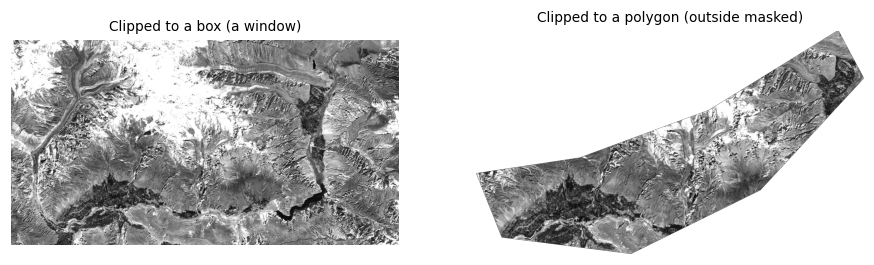

In [3]:
AOI = [74.55, 36.28, 74.95, 36.45]
valley = gpd.GeoDataFrame(geometry=[Polygon([(74.60, 36.30), (74.70, 36.29), (74.80, 36.33), (74.88, 36.40),
                                             (74.86, 36.43), (74.76, 36.38), (74.66, 36.35), (74.58, 36.34)])], crs="EPSG:4326")
with rasterio.open(item.assets["B04"].href) as src:
    win = from_bounds(*transform_bounds("EPSG:4326", src.crs, *AOI), src.transform)
    red = src.read(1, window=win)
    wtf = src.window_transform(win)
    poly = valley.to_crs(src.crs)
    clipped, ctf = rio_mask(src, poly.geometry, crop=True, nodata=0)
print("box window:", red.shape, "| polygon clip:", clipped.shape[1:], "| pixels inside polygon:", int((clipped[0] > 0).sum()))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].imshow(red, cmap="gray", vmin=1000, vmax=4000)
ax[0].set_title("Clipped to a box (a window)", fontsize=9)
ax[1].imshow(np.ma.masked_equal(clipped[0], 0), cmap="gray", vmin=1000, vmax=4000)
ax[1].set_title("Clipped to a polygon (outside masked)", fontsize=9)
for a in ax:
    a.set_axis_off()
plt.show()

# Reprojection and resampling

To combine data on different grids (a 10 m UTM image and a 30 m DEM in degrees, say) one must be **reprojected** onto
the other's grid. Each new pixel takes its value from the old pixels near its centre, by a **resampling** rule:

* **nearest neighbour**: the closest old pixel. Keeps original values exactly; the only correct choice for categories
  (land cover classes, masks, quality flags), which must never be averaged.
* **bilinear**: a distance-weighted mean of the 4 nearest pixels. Smooth; good for continuous values (reflectance,
  elevation, temperature).
* **cubic**: uses 16 pixels; sharper, but can overshoot past the original range.
* **average**: the mean of all old pixels inside each new one; the right choice when making pixels much larger.

Below, the red band is reprojected to geographic coordinates (EPSG:4326) at about 30 m, with each rule, and we compare
the statistics. Averaging changes extremes most: bright and dark single pixels are smoothed away.

In [4]:
dst_crs = "EPSG:4326"
tf, w, h = calculate_default_transform(src.crs, dst_crs, red.shape[1], red.shape[0], *rasterio.transform.array_bounds(*red.shape, wtf), resolution=0.0003)
rows = []
for rule in [Resampling.nearest, Resampling.bilinear, Resampling.cubic, Resampling.average]:
    out = np.zeros((h, w), "float32")
    reproject(red.astype("float32"), out, src_transform=wtf, src_crs=src.crs, dst_transform=tf, dst_crs=dst_crs,
              resampling=rule, src_nodata=0, dst_nodata=0)
    v = out[out > 0]
    rows.append(dict(rule=rule.name, pixels=v.size, mean=v.mean(), min=v.min(), max=v.max(), std=v.std()))
v = red[red > 0]
rows.insert(0, dict(rule="original 10 m", pixels=v.size, mean=v.mean(), min=v.min(), max=v.max(), std=v.std()))
pd.DataFrame(rows).round(1)

,rule,pixels,mean,min,max,std
0,original 10 m,6808735,3214.9,437.000000,16753.000000,2089.7
1,nearest,760593,3214.9,1012.000000,16751.000000,2090.2
2,bilinear,760593,3215.4,1039.599976,16621.699219,1999.1
3,cubic,760593,3215.4,974.000000,17851.199219,2036.2
4,average,761906,3216.2,1038.400024,16703.900391,2024.4


# Mosaicking: joining tiles

Sentinel-2 is cut into 110 by 110 km tiles on the MGRS grid; Landsat into path/row scenes. An area across a tile
boundary needs a **mosaic**. Tiles from the same orbit and date line up exactly (same sun, same atmosphere); tiles from
different dates show seams. Where tiles overlap, a rule decides which value wins: the first tile, the last, or the
mean. Here we join two tiles from the same orbit and day.

date with 2 tiles: 2024-09-23 ['43SDA', '43SEA']


mosaic: (3, 558, 1945) (bands, rows, columns) at 60 m


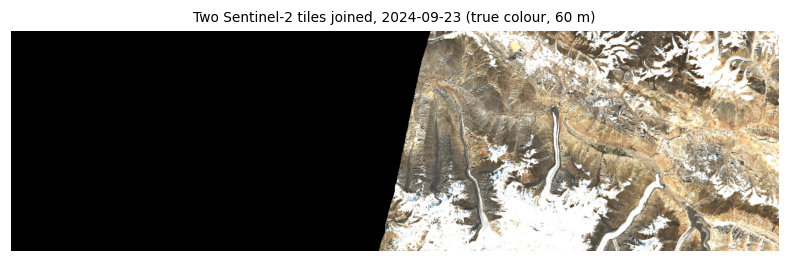

In [5]:
WIDE = [74.3, 36.3, 75.6, 36.6]                          # wider than one tile: reaches the next tile east
wide_items = catalog.search(collections=["sentinel-2-l2a"], bbox=WIDE, datetime="2024-06-01/2024-09-30",
                            query={"eo:cloud_cover": {"lt": 20}}).items()
by_tile = {}
for i in wide_items:
    by_tile.setdefault(i.properties["datetime"][:10], {})[i.properties["s2:mgrs_tile"]] = i
day, tiles = next((d, t) for d, t in sorted(by_tile.items(), key=lambda kv: -len(kv[1])) if len(t) >= 2)
print("date with", len(tiles), "tiles:", day, sorted(tiles))
srcs = [rasterio.open(t.assets["visual"].href) for t in list(tiles.values())[:2]]
bounds = transform_bounds("EPSG:4326", srcs[0].crs, *WIDE)
mosaic, mtf = merge(srcs, bounds=bounds, res=60, resampling=Resampling.average, method="first", nodata=0)
for s in srcs:
    s.close()
print("mosaic:", mosaic.shape, "(bands, rows, columns) at 60 m")
plt.figure(figsize=(9, 3.2))
plt.imshow(np.moveaxis(mosaic, 0, -1))
plt.title(f"Two Sentinel-2 tiles joined, {day} (true colour, 60 m)", fontsize=9)
plt.axis("off")
plt.show()

# Stacking bands of different pixel sizes

Analysis is easiest with all bands in one 3-D array (band, row, column) on **one grid**. Sentinel-2's bands come at
10, 20 and 60 m, so the 20 m bands are resampled to 10 m (bilinear, since reflectance is continuous) and the 20 m
**scene classification layer** (SCL), which holds categories, with nearest neighbour.

In [6]:
STUDY = [74.60, 36.30, 74.80, 36.42]
def read_to(item, key, bbox, shape, rule):
    with rasterio.open(item.assets[key].href) as s:
        win = from_bounds(*transform_bounds("EPSG:4326", s.crs, *bbox), s.transform)
        return s.read(1, window=win, out_shape=shape, resampling=rule)

with rasterio.open(item.assets["B02"].href) as s:
    win = from_bounds(*transform_bounds("EPSG:4326", s.crs, *STUDY), s.transform)
    shape = s.read(1, window=win).shape
keys = ["B02", "B03", "B04", "B08", "B11", "B12"]
stack = np.stack([read_to(item, k, STUDY, shape, Resampling.bilinear) for k in keys])
scl = read_to(item, "SCL", STUDY, shape, Resampling.nearest)
print("stack:", stack.shape, stack.dtype, "| SCL:", scl.shape, "| SCL classes present:", sorted(np.unique(scl).tolist()))

stack: (6, 1337, 1798) uint16 | SCL: (1337, 1798) | SCL classes present: [2, 3, 4, 5, 6, 7, 8, 9, 11]


# Masking no-data and cloud

Two kinds of pixel must be removed before statistics. **No-data** pixels (outside the image, value 0 here) carry no
measurement. **Cloud and cloud shadow** hide the ground. Sentinel-2 Level-2A includes the **scene classification
layer**, a per-pixel label from the Sen2Cor processor:

| SCL | Meaning | SCL | Meaning |
|---|---|---|---|
| 0 | no data | 6 | water |
| 1 | saturated or defective | 7 | unclassified |
| 2 | dark area | 8 | cloud, medium probability |
| 3 | cloud shadow | 9 | cloud, high probability |
| 4 | vegetation | 10 | thin cirrus |
| 5 | not vegetated | 11 | snow or ice |

A mask is a true/false array; numpy's `where` replaces masked values with `NaN` ("not a number"), which statistics
functions such as `nanmean` skip. Masks are never perfect: SCL confuses bright snow with cloud and dark shadows with
water, especially in mountains, so always look at what you remove. In the output below about a sixth of the valley is
"dark area": mostly slopes in the shadow of mountains, which the mask keeps, since they are real ground; their values
are low because little sunlight reaches them, the topographic effect again.

In [7]:
names = {0: "no data", 1: "saturated", 2: "dark area", 3: "cloud shadow", 4: "vegetation", 5: "not vegetated", 6: "water",
         7: "unclassified", 8: "cloud medium", 9: "cloud high", 10: "cirrus", 11: "snow or ice"}
v, n = np.unique(scl, return_counts=True)
print(pd.Series(n / n.sum() * 100, index=[names[int(x)] for x in v]).round(1).to_string(), "\n(% of pixels)")
bad = np.isin(scl, [0, 1, 3, 8, 9, 10])
refl = np.where(bad[None], np.nan, (stack.astype("float32") - 1000) / 10000)
print("kept", f"{100 * (~bad).mean():.1f}% of pixels")

dark area        16.5
cloud shadow      0.0
vegetation        7.7
not vegetated    52.4
water             0.3
unclassified      0.3
cloud medium      0.1
cloud high        0.0
snow or ice      22.6 
(% of pixels)
kept 99.9% of pixels


# Composites over time

One image is one moment, often with cloud. A **composite** combines many dates into one cloud-free picture by taking,
at each pixel, a statistic over the clear observations. The **median** is the usual choice: it ignores the few cloudy
or shadowed values that slip past the mask, which a mean would not. The cost is that a composite no longer shows one
moment, so it suits slowly changing things (land cover) better than quick ones (snow on a given day).

Below, every summer 2024 image of the study area is masked and the median taken. We use the 20 m bands to keep memory
low.

15 dates; clear share per date: [0.78, 0.6, 0.64, 0.95, 0.88, 0.95, 1.0, 0.71, 0.82, 0.83, 0.46, 0.88, 0.27, 1.0, 0.72]
clear observations per pixel: min 3 median 12 max 15


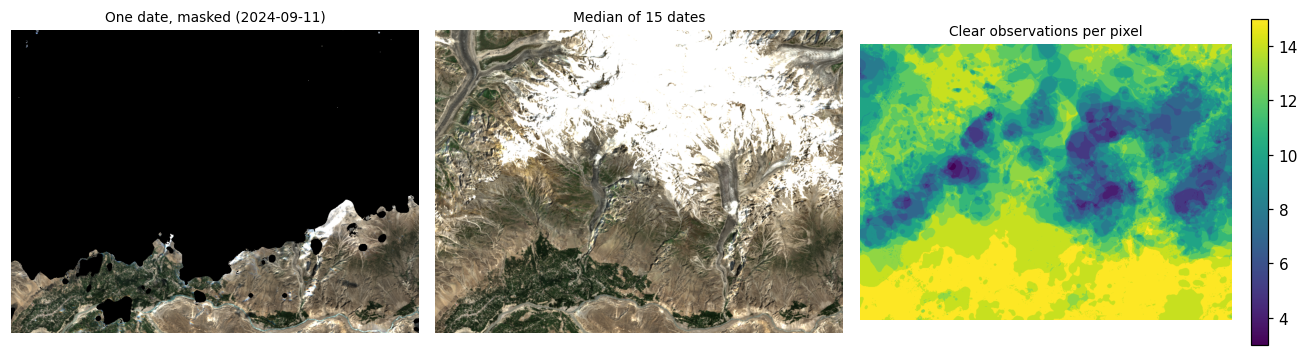

In [8]:
use = [i for i in items if i.properties["s2:mgrs_tile"] == item.properties["s2:mgrs_tile"]]
with rasterio.open(item.assets["B11"].href) as s:
    win = from_bounds(*transform_bounds("EPSG:4326", s.crs, *STUDY), s.transform)
    shape20 = s.read(1, window=win).shape
layers, clear = [], []
for it in use:
    s_cl = read_to(it, "SCL", STUDY, shape20, Resampling.nearest)
    ok = ~np.isin(s_cl, [0, 1, 3, 8, 9, 10])
    off = -1000 if float(it.properties["s2:processing_baseline"]) >= 4 else 0
    rgb = np.stack([read_to(it, k, STUDY, shape20, Resampling.average) for k in ["B04", "B03", "B02"]]).astype("float32")
    layers.append(np.where(ok[None], (rgb + off) / 10000, np.nan))
    clear.append(round(float(ok.mean()), 2))
cube = np.stack(layers)                                   # date, band, row, column
median = np.nanmedian(cube, axis=0)
count = np.isfinite(cube[:, 0]).sum(0)
print(len(use), "dates; clear share per date:", clear)
print("clear observations per pixel: min", int(count.min()), "median", int(np.median(count)), "max", int(count.max()))
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
show = lambda a: np.clip(np.moveaxis(a, 0, -1) / 0.35, 0, 1)
worst = int(np.argmin(clear))
ax[0].imshow(show(np.nan_to_num(cube[worst], nan=0)))
ax[0].set_title(f"One date, masked ({use[worst].properties['datetime'][:10]})", fontsize=9)
ax[1].imshow(show(np.nan_to_num(median, nan=0)))
ax[1].set_title(f"Median of {len(use)} dates", fontsize=9)
im = ax[2].imshow(count, cmap="viridis")
ax[2].set_title("Clear observations per pixel", fontsize=9)
plt.colorbar(im, ax=ax[2], fraction=0.04)
for a in ax:
    a.set_axis_off()
plt.tight_layout()
plt.show()

# Saving the result properly

A result is only useful if others can open it in any GIS and know what it is. Save rasters as **Cloud-Optimised
GeoTIFF** with the CRS and transform, a no-data value, compression, band descriptions, and a few words of metadata on
how it was made. (Reading it back reports the driver as GTiff: a COG is an ordinary GeoTIFF with its internal tiles
and overviews arranged for reading over the web.)

In [9]:
with rasterio.open(item.assets["B11"].href) as s:
    crs20, tf20 = s.crs, rasterio.windows.transform(win, s.transform)
profile = dict(driver="COG", dtype="float32", count=3, width=shape20[1], height=shape20[0], crs=crs20,
               transform=tf20, nodata=np.nan, compress="deflate")
with rasterio.open("hunza_median_summer2024.tif", "w", **profile) as dst:
    dst.write(median.astype("float32"))
    for k, name in enumerate(["red", "green", "blue"], 1):
        dst.set_band_description(k, f"{name} surface reflectance")
    dst.update_tags(source="Sentinel-2 L2A via Microsoft Planetary Computer", method=f"per-pixel median of {len(use)} dates, SCL cloud mask",
                    period="2024-06-01/2024-09-30")
with rasterio.open("hunza_median_summer2024.tif") as chk:
    print(chk.profile["driver"], chk.crs, chk.res, chk.count, "bands |", chk.descriptions, "|", chk.tags()["method"])

GTiff EPSG:32643 (20.0, 20.0) 3 bands | ('red surface reflectance', 'green surface reflectance', 'blue surface reflectance') | per-pixel median of 15 dates, SCL cloud mask


# What to remember

* Know your CRS, and convert vectors to the raster's CRS, not the other way round, unless you mean to resample.
* Read only the window you need; clip to polygons after.
* Nearest neighbour for categories, bilinear or average for continuous values.
* Mask no-data and cloud before any statistic, and look at what the mask removed.
* A median composite gives a clear picture of a season, at the cost of losing the moment.
* Save with CRS, no-data, descriptions and a record of how the file was made.

**Exercises.** (1) Repeat the composite with the mean instead of the median and find where they differ most. (2)
Reproject the composite to UTM zone 43 at 30 m with each resampling rule and compare. (3) Draw a polygon around your
own study area and compute the share of clear observations inside it per month.